# Analisis Mobilitas DIY: Dampak Peristiwa dan Pola Komuter

Mata kuliah Rekayasa Data, Universitas Gadjah Mada.

## 1. Pendahuluan

Data mobilitas dari perangkat seluler dapat menggambarkan di mana orang berada dan kapan mereka bergerak. Notebook ini memakai dataset *JogjaPulse*, yaitu jumlah perangkat teragregasi per kapanewon per jam di Daerah Istimewa Yogyakarta (DIY) pada 1 Desember 2021 sampai 30 April 2022. Periode ini mencakup libur Natal dan Tahun Baru (Nataru), gelombang Omicron, Ramadan 1443 H, dan masa menjelang mudik Lebaran.

Pertanyaan penelitian:

- **RQ1 (utama):** Bagaimana sebaran kehadiran antarkapanewon dan pola waktunya bergeser saat Nataru, gelombang Omicron, Ramadan, dan menjelang mudik Lebaran dibanding periode acuan di segmen panel yang sama? Kapanewon mana yang pangsanya paling berubah?
- **RQ2 (pelengkap):** Kapanewon mana yang berperan sebagai pusat aktivitas dan mana yang sebagai kawasan tempat tinggal, dan ke mana arus pergerakan utamanya?

RQ1 semula ingin mengukur besar perubahan mobilitas total. Rumusannya diubah karena jumlah perangkat yang teramati berubah drastis selama periode data (lihat subbagian 4.1), sehingga perubahan total tidak dapat diukur secara sahih.

Data yang dipakai:

| Data | Sumber | Kegunaan |
|---|---|---|
| `presence_kapanewon_hourly.csv` | JogjaPulse (Zenodo) | Deret waktu, pangsa, profil jam, rasio siang/malam |
| `od_home_visits_kapanewon_monthly.csv` | JogjaPulse (Zenodo) | Arus asal-tujuan |
| `kapanewon_diy.geojson` | cahyadsn/wilayah_boundaries melalui aaronsanger/idn-geojson | Peta dan centroid |
| Kalender peristiwa | Dikurasi manual (sel 5.2) | Penanda periode event |

## 2. Pengambilan Data

Data dibaca dari folder `data/`. Jika file JogjaPulse belum ada, file diunduh dari Zenodo (record 23157460) lalu dicek MD5-nya. Batas wilayah diunduh dari GitHub jika belum ada.

In [1]:
import hashlib
import json
from pathlib import Path

import duckdb
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from matplotlib.colors import TwoSlopeNorm
from scipy.stats import spearmanr

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False})
FIGSIZE = (12.8, 7.2)

DATA = Path("data")
FIG = Path("figures")
DATA.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)

ZENODO = "https://zenodo.org/api/records/23157460"
FILES = ["presence_kapanewon_hourly.csv", "od_home_visits_kapanewon_monthly.csv"]
GEO_URL = "https://raw.githubusercontent.com/aaronsanger/idn-geojson/main/districts/{}.geojson"
KAB = ["34_01", "34_02", "34_03", "34_04", "34_71"]


def md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


missing = [f for f in FILES if not (DATA / f).exists()]
if missing:
    rec = requests.get(ZENODO, timeout=60).json()
    meta = {f["key"]: f for f in rec["files"]}
    for name in missing:
        r = requests.get(meta[name]["links"]["self"], timeout=600)
        (DATA / name).write_bytes(r.content)
        assert md5(DATA / name) == meta[name]["checksum"].split(":")[1], name

if not (DATA / "kapanewon_diy.geojson").exists():
    feats = []
    for k in KAB:
        for f in requests.get(GEO_URL.format(k), timeout=60).json()["features"]:
            pr = f["properties"]
            f["properties"] = {"kapanewon_code": pr["code"], "nama": pr["name"].replace("KEC. ", ""),
                               "kab_code": pr["parent_id"], "source": pr["source"]}
            feats.append(f)
    (DATA / "kapanewon_diy.geojson").write_text(json.dumps({"type": "FeatureCollection", "features": feats}))

for f in FILES:
    print(f, md5(DATA / f))

presence_kapanewon_hourly.csv 90a4a8ae6eb68abc68f7a1021a51cce8
od_home_visits_kapanewon_monthly.csv 5857291c608dd5335f6d8833c1ec7b7a


In [2]:
pres_raw = pd.read_csv(DATA / "presence_kapanewon_hourly.csv", dtype={"kab_code": str, "kapanewon_code": str})
od_raw = pd.read_csv(DATA / "od_home_visits_kapanewon_monthly.csv",
                     dtype={"origin_kab_code": str, "origin_code": str, "dest_kab_code": str, "dest_code": str})
geo = gpd.read_file(DATA / "kapanewon_diy.geojson")
pres_raw.shape, od_raw.shape, geo.shape

((230418, 8), (9894, 11), (78, 6))

## 3. Pemahaman Data

Definisi kolom diambil dari `README.md` dataset. Hal penting dari README:

- `n_maids` adalah jumlah perangkat **berbeda** yang hadir. Nilai ini **tidak aditif**: satu perangkat yang hadir di dua jam atau dua kapanewon dihitung di keduanya. Karena itu `n_maids` tidak dijumlahkan lintas jam untuk mendapatkan total harian.
- Baris dengan kurang dari 5 perangkat dihapus (k-anonim, k = 5). Baris yang hilang berarti "kurang dari 5", bukan nol.
- Semua tanggal dan jam sudah dalam WIB (UTC+7), jadi tidak perlu konversi zona waktu.

In [3]:
pres_raw.head()

,kab_code,kab_kota,kapanewon_code,kapanewon,date,hour,n_maids,n_pings
0,34.01,KULON PROGO,34.01.01,TEMON,2021-12-01,0,16,66
1,34.01,KULON PROGO,34.01.02,WATES,2021-12-01,0,58,101
2,34.01,KULON PROGO,34.01.03,PANJATAN,2021-12-01,0,11,32
3,34.01,KULON PROGO,34.01.04,GALUR,2021-12-01,0,9,50
4,34.01,KULON PROGO,34.01.05,LENDAH,2021-12-01,0,14,74


In [4]:
od_raw.head()

,month,origin_kab_code,origin_kab_kota,origin_code,origin_kapanewon,dest_kab_code,dest_kab_kota,dest_code,dest_kapanewon,n_maids,reduced_quality
0,2021-12,34.01,KULON PROGO,34.01.01,TEMON,34.01,KULON PROGO,34.01.01,TEMON,569,False
1,2021-12,34.01,KULON PROGO,34.01.01,TEMON,34.01,KULON PROGO,34.01.02,WATES,85,False
2,2021-12,34.01,KULON PROGO,34.01.01,TEMON,34.01,KULON PROGO,34.01.03,PANJATAN,42,False
3,2021-12,34.01,KULON PROGO,34.01.01,TEMON,34.01,KULON PROGO,34.01.04,GALUR,16,False
4,2021-12,34.01,KULON PROGO,34.01.01,TEMON,34.01,KULON PROGO,34.01.05,LENDAH,8,False


In [5]:
pres_raw.dtypes.to_frame('presence').join(od_raw.dtypes.rename('od'), how='outer')

,presence,od
date,str,NaN
dest_code,NaN,str
dest_kab_code,NaN,str
dest_kab_kota,NaN,str
dest_kapanewon,NaN,str
hour,int64,NaN
kab_code,str,NaN
kab_kota,str,NaN
kapanewon,str,NaN
kapanewon_code,str,NaN


In [6]:
kamus = pd.DataFrame([
    ("presence", "kab_code, kab_kota", "string", "Kode dan nama kabupaten/kota"),
    ("presence", "kapanewon_code, kapanewon", "string", "Kode BPS (34.xx.xx) dan nama kapanewon"),
    ("presence", "date", "tanggal", "Tanggal (WIB)"),
    ("presence", "hour", "int", "Jam 0-23 (WIB); 8 = 08:00-08:59"),
    ("presence", "n_maids", "int", "Perangkat berbeda yang hadir pada jam itu (>= 5, tidak aditif)"),
    ("presence", "n_pings", "int", "Jumlah ping (aditif, tidak dipakai)"),
    ("od", "month", "string", "Bulan YYYY-MM"),
    ("od", "origin_code, origin_kapanewon", "string", "Kapanewon rumah (malam 22:00-05:59)"),
    ("od", "dest_code, dest_kapanewon", "string", "Kapanewon yang dikunjungi siang (08:00-17:59)"),
    ("od", "n_maids", "int", "Perangkat berbeda dari asal yang teramati di tujuan dalam bulan itu (>= 5)"),
    ("od", "reduced_quality", "bool", "True untuk Maret-April 2022"),
], columns=["tabel", "kolom", "tipe", "arti"])
grain = pd.DataFrame({
    "tabel": ["presence", "od", "geo"],
    "grain": ["kapanewon x tanggal x jam", "bulan x kapanewon asal x kapanewon tujuan", "kapanewon"],
    "baris": [len(pres_raw), len(od_raw), len(geo)],
})
display(kamus)
display(grain)

,tabel,kolom,tipe,arti
0,presence,"kab_code, kab_kota",string,Kode dan nama kabupaten/kota
1,presence,"kapanewon_code, kapanewon",string,Kode BPS (34.xx.xx) dan nama kapanewon
2,presence,date,tanggal,Tanggal (WIB)
3,presence,hour,int,Jam 0-23 (WIB); 8 = 08:00-08:59
4,presence,n_maids,int,Perangkat berbeda yang hadir pada jam itu (>= ...
5,presence,n_pings,int,"Jumlah ping (aditif, tidak dipakai)"
6,od,month,string,Bulan YYYY-MM
7,od,"origin_code, origin_kapanewon",string,Kapanewon rumah (malam 22:00-05:59)
8,od,"dest_code, dest_kapanewon",string,Kapanewon yang dikunjungi siang (08:00-17:59)
9,od,n_maids,int,Perangkat berbeda dari asal yang teramati di t...


,tabel,grain,baris
0,presence,kapanewon x tanggal x jam,230418
1,od,bulan x kapanewon asal x kapanewon tujuan,9894
2,geo,kapanewon,78


In [7]:
pres_raw[['kab_code', 'kapanewon_code', 'kapanewon', 'date', 'hour']].nunique()

kab_code            5
kapanewon_code     78
kapanewon          77
date              151
hour               24
dtype: int64

Ada 78 kode kapanewon tetapi hanya 77 nama, karena nama **JETIS** dipakai di Bantul (34.02.09) dan di Kota Yogyakarta (34.71.02). Semua join wilayah memakai kode BPS.

In [8]:
pres_raw.drop_duplicates(['kapanewon_code', 'kapanewon', 'kab_kota']).query('kapanewon == "JETIS"')

,kab_code,kab_kota,kapanewon_code,kapanewon,date,hour,n_maids,n_pings
19,34.02,BANTUL,34.02.09,JETIS,2021-12-01,0,61,141
54,34.71,YOGYAKARTA,34.71.02,JETIS,2021-12-01,0,46,196


## 4. Pemeriksaan Kualitas Data

In [9]:
pres_raw["date"] = pd.to_datetime(pres_raw["date"])
n_kpw = pres_raw["kapanewon_code"].nunique()
n_hari = pres_raw["date"].nunique()
od_raw["n_maids"] = od_raw["n_maids"].astype(int)

kualitas = pd.DataFrame({
    "presence": {
        "baris": len(pres_raw),
        "duplikat kunci": pres_raw.duplicated(["kapanewon_code", "date", "hour"]).sum(),
        "null": int(pres_raw.isna().sum().sum()),
        "rentang": f"{pres_raw.date.min():%Y-%m-%d} s.d. {pres_raw.date.max():%Y-%m-%d}, jam {pres_raw.hour.min()}-{pres_raw.hour.max()}",
        "baris harapan": n_hari * 24 * n_kpw,
        "kelengkapan (%)": round(len(pres_raw) / (n_hari * 24 * n_kpw) * 100, 1),
        "n_maids minimum": pres_raw.n_maids.min(),
    },
    "od": {
        "baris": len(od_raw),
        "duplikat kunci": od_raw.duplicated(["month", "origin_code", "dest_code"]).sum(),
        "null": int(od_raw.isna().sum().sum()),
        "rentang": f"{od_raw.month.min()} s.d. {od_raw.month.max()}",
        "baris harapan": od_raw.month.nunique() * n_kpw * n_kpw,
        "kelengkapan (%)": round(len(od_raw) / (od_raw.month.nunique() * n_kpw ** 2) * 100, 1),
        "n_maids minimum": od_raw.n_maids.min(),
    },
})
kualitas

,presence,od
baris,230418,9894
duplikat kunci,0,0
null,0,0
rentang,"2021-12-01 s.d. 2022-04-30, jam 0-23",2021-12 s.d. 2022-04
baris harapan,282672,30420
kelengkapan (%),81.5,32.5
n_maids minimum,5,5


Tidak ada duplikat kunci maupun nilai null, dan nilai minimum `n_maids` = 5 sesuai ambang k-anonim. Tabel presence hanya terisi 81,5% dari kombinasi kapanewon x hari x jam yang mungkin. Tabel OD hanya terisi 32,5% dari kombinasi pasangan yang mungkin, karena sebagian besar pasangan antarwilayah yang jauh memiliki kurang dari 5 perangkat.

### 4.1 Masalah Panel Perangkat

README dataset menyebutkan bahwa jumlah perangkat yang teramati tidak konstan. Perubahan ini berasal dari komposisi sampel penyedia data, bukan dari perubahan mobilitas penduduk. Di bawah ini dihitung indeks kehadiran harian DIY, yaitu rata-rata `n_maids` per jam (jumlah seluruh baris pada hari itu dibagi 24).

In [10]:
idx_diy = pres_raw.groupby("date")["n_maids"].sum() / 24
lompat = idx_diy.pct_change() * 100
lompat.sort_values().head(4).round(1).to_frame("perubahan dari hari sebelumnya (%)")

,perubahan dari hari sebelumnya (%)
date,
2022-02-16,-59.7
2022-03-08,-48.0
2022-02-20,-46.1
2022-01-01,-40.7


In [11]:
BREAKS = pd.to_datetime(["2022-01-01", "2022-02-16"])
ANOMALI = pd.to_datetime(["2022-03-08"])


def segmen(d):
    return np.select([d < BREAKS[0], d < BREAKS[1]], ["S1", "S2"], "S3")


seg_tab = (idx_diy.to_frame("indeks").assign(segmen=lambda x: segmen(x.index))
           .drop(ANOMALI).groupby("segmen")["indeks"].agg(["mean", "min", "max", "count"]).round(0))
seg_tab.index = ["S1: 1-31 Des 2021", "S2: 1 Jan-15 Feb 2022", "S3: 16 Feb-30 Apr 2022"]
seg_tab

,mean,min,max,count
S1: 1-31 Des 2021,8663.0,4336.0,11130.0,31
S2: 1 Jan-15 Feb 2022,6888.0,4428.0,11395.0,46
S3: 16 Feb-30 Apr 2022,1442.0,649.0,5127.0,73


In [12]:
pres_raw["bulan"] = pres_raw["date"].dt.to_period("M")
pr = pres_raw[~pres_raw["date"].isin(ANOMALI)]
hari_bulan = pr.groupby("bulan")["date"].nunique()
slot = (pr.groupby(["kapanewon_code", "bulan"]).size().unstack() / (hari_bulan * 24) * 100)
ringkas_bulan = pd.DataFrame({
    "median slot terisi (%)": slot.median(),
    "minimum (%)": slot.min(),
    "kapanewon >= 80%": (slot >= 80).sum(),
}).round(1)
ringkas_bulan.index = ringkas_bulan.index.astype(str)
ringkas_bulan

,median slot terisi (%),minimum (%),kapanewon >= 80%
bulan,,,
2021-12,99.9,40.7,70
2022-01,99.7,31.3,68
2022-02,97.2,23.5,68
2022-03,81.0,1.1,40
2022-04,62.9,1.0,27


Indeks kehadiran DIY turun sekitar 41% pada 1 Januari 2022 dan 60% pada 16 Februari 2022, dibanding hari sebelumnya. Rata-rata indeks turun dari 8.663 perangkat/jam di S1 menjadi 1.442 di S3. Kelengkapan juga memburuk. Median slot jam yang terisi per kapanewon masih 99,9% di Desember tetapi tinggal 62,9% di April. Kapanewon dengan kelengkapan >= 80% berkurang dari 70 menjadi 27. Perubahan sebesar ini tidak mungkin disebabkan perilaku penduduk, jadi angka mentah tidak boleh dibandingkan antarsegmen.

Konsekuensi bagi analisis:

1. `n_maids` tidak dijumlahkan lintas jam. Indeks harian kapanewon adalah rata-rata `n_maids` per jam (jumlah jam yang terpublikasi dibagi 24). Slot yang tersupresi tidak diisi 0 maupun nilai lain.
2. Data dibagi menjadi tiga segmen panel: S1 (1-31 Des), S2 (1 Jan-15 Feb), dan S3 (16 Feb-30 Apr). Tanggal 8 Maret 2022 dikeluarkan karena anomali. Setiap event dibandingkan dengan acuan di segmen yang sama.
3. Perbandingan antarwaktu memakai **pangsa** kapanewon terhadap total, bukan angka mentah.
4. Pangsa dihitung pada **himpunan kapanewon tetap**, yaitu kapanewon dengan slot jam terisi >= 80% di setiap bulan dalam jendela perbandingan. Tanpa syarat ini, makin banyak baris kapanewon pedesaan yang tersupresi di bulan akhir, sehingga pangsa kawasan kota akan naik secara artifisial. Ada dua himpunan:
   - **Set A** (Des-Feb) dipakai untuk Nataru dan Omicron.
   - **Set B** (Mar-Apr) dipakai untuk Ramadan dan pra-mudik.

In [13]:
nama = pres_raw.drop_duplicates("kapanewon_code").set_index("kapanewon_code")[["kapanewon", "kab_kota"]]
bln = lambda *m: [pd.Period(x, "M") for x in m]
SET_A = sorted(slot.index[(slot[bln("2021-12", "2022-01", "2022-02")] >= 80).all(axis=1)])
SET_B = sorted(slot.index[(slot[bln("2022-03", "2022-04")] >= 80).all(axis=1)])

hari_kpw = pres_raw.groupby("kapanewon_code")["date"].nunique() / n_hari * 100
KURANG_80_HARI = sorted(hari_kpw.index[hari_kpw < 80])

cakupan = (nama.assign(set_A=lambda x: x.index.isin(SET_A), set_B=lambda x: x.index.isin(SET_B))
           .groupby("kab_kota")[["set_A", "set_B"]].sum())
cakupan["total"] = nama.groupby("kab_kota").size()
print("Set A:", len(SET_A), "kapanewon; Set B:", len(SET_B), "kapanewon")
print("Kelengkapan hari < 80% (dikeluarkan dari analisis per wilayah):", nama.loc[KURANG_80_HARI, "kapanewon"].tolist())
cakupan

Set A: 66 kapanewon; Set B: 26 kapanewon
Kelengkapan hari < 80% (dikeluarkan dari analisis per wilayah): ['RONGKOP', 'GIRISUBO', 'PURWOSARI']


,set_A,set_B,total
kab_kota,,,
BANTUL,17,7,17
GUNUNGKIDUL,9,1,18
KULON PROGO,11,0,12
SLEMAN,17,11,17
YOGYAKARTA,12,7,14


In [14]:
print("Dikeluarkan dari Set A:")
print(", ".join(nama.loc[~nama.index.isin(SET_A), "kapanewon"].str.title()))
print("\nDikeluarkan dari Set B:")
print(", ".join(nama.loc[~nama.index.isin(SET_B), "kapanewon"].str.title()))

Dikeluarkan dari Set A:
Girimulyo, Gedongtengen, Ngampilan, Panggang, Ngawen, Paliyan, Saptosari, Girisubo, Purwosari, Rongkop, Tanjungsari, Tepus

Dikeluarkan dari Set B:
Temon, Wates, Panjatan, Galur, Lendah, Sentolo, Pengasih, Kokap, Girimulyo, Nanggulan, Kalibawang, Srandakan, Sanden, Kretek, Pundong, Bambanglipuro, Pajangan, Imogiri, Dlingo, Pleret, Piyungan, Playen, Patuk, Semanu, Karangmojo, Ponjong, Semin, Gedangsari, Moyudan, Minggir, Prambanan, Tempel, Turi, Cangkringan, Danurejan, Gedongtengen, Ngampilan, Wirobrajan, Mantrijeron, Pakualaman, Kotagede, Panggang, Ngawen, Nglipar, Paliyan, Saptosari, Girisubo, Purwosari, Samigaluh, Rongkop, Tanjungsari, Tepus


Set A berisi 66 kapanewon dan masih mencakup kelima kabupaten/kota. Kapanewon yang dikeluarkan sebagian besar berada di Gunungkidul selatan. Set B hanya berisi 26 kapanewon, hampir semuanya di Sleman, Bantul utara, dan Kota Yogyakarta, sedangkan Kulon Progo tidak terwakili sama sekali. Hasil Ramadan dan pra-mudik karena itu hanya berlaku untuk kawasan perkotaan. Tiga kapanewon (Rongkop, Girisubo, Purwosari) terisi kurang dari 80% hari dan sudah otomatis keluar dari kedua set.

## 5. Pembersihan & Transformasi

### 5.1 Konversi tipe, segmen, dan join wilayah

In [15]:
pres = pres_raw.loc[~pres_raw["date"].isin(ANOMALI)].copy()
pres["segmen"] = segmen(pres["date"])
pres["dow"] = pres["date"].dt.day_of_week
print("Baris dikeluarkan (8 Mar 2022):", len(pres_raw) - len(pres))

kode_data = set(pres["kapanewon_code"])
kode_geo = set(geo["kapanewon_code"])
print("Kode di data tetapi tidak di peta:", sorted(kode_data - kode_geo))
print("Kode di peta tetapi tidak di data:", sorted(kode_geo - kode_data))
cek_nama = nama.join(geo.set_index("kapanewon_code")["nama"])
print("Nama berbeda untuk kode yang sama:", (cek_nama["kapanewon"] != cek_nama["nama"]).sum())

geo = geo.merge(nama.reset_index(), on="kapanewon_code", how="left")
geo_utm = geo.to_crs(32749)
centroid = geo_utm.set_index("kapanewon_code").geometry.centroid

Baris dikeluarkan (8 Mar 2022): 993
Kode di data tetapi tidak di peta: []
Kode di peta tetapi tidak di data: []
Nama berbeda untuk kode yang sama: 0


### 5.2 Kalender peristiwa

| Event | Periode | Segmen | Acuan | Sumber |
|---|---|---|---|---|
| Nataru | 24-31 Des 2021 | S1 | 6-19 Des 2021 (S1) | Libur Natal 25 Des. Tanggal 1 Jan tidak dipakai karena jatuh di titik putus panel |
| Omicron | 1-28 Feb 2022 | S2/S3 | 6-19 Des 2021, hanya pangsa | Kasus harian nasional mencapai puncak sekitar 16 Feb 2022 (Satgas COVID-19 / Kemenkes) |
| Ramadan | 3-24 Apr 2022 | S3 | Maret 2022 (S3) | 1 Ramadan 1443 H = 3 Apr 2022 menurut sidang isbat Kemenag |
| Pra-mudik | 25-30 Apr 2022 | S3 | Maret 2022 (S3) | Cuti bersama mulai 29 Apr 2022; Idul Fitri 2 Mei 2022 (SKB 3 Menteri) |

Acuan Maret mencakup 1-31 Maret 2022, tanpa 3 Maret (libur Nyepi) dan 8 Maret (anomali). Masa Omicron berimpit dengan titik putus panel 16 Februari, sehingga perubahan pangsa pada masa itu tidak dapat dipisahkan dari perubahan komposisi sampel.

In [16]:
EVENTS = pd.DataFrame([
    ("Nataru", "2021-12-24", "2021-12-31", "A", "des"),
    ("Omicron", "2022-02-01", "2022-02-28", "A", "des"),
    ("Ramadan", "2022-04-03", "2022-04-24", "B", "mar"),
    ("Pra-mudik", "2022-04-25", "2022-04-30", "B", "mar"),
], columns=["event", "mulai", "selesai", "set", "acuan"])
EVENTS[["mulai", "selesai"]] = EVENTS[["mulai", "selesai"]].apply(pd.to_datetime)
ACUAN = {
    "des": pd.date_range("2021-12-06", "2021-12-19"),
    "mar": pd.date_range("2022-03-01", "2022-03-31").drop(pd.to_datetime(["2022-03-03", "2022-03-08"])),
}
EVENTS

,event,mulai,selesai,set,acuan
0,Nataru,2021-12-24,2021-12-31,A,des
1,Omicron,2022-02-01,2022-02-28,A,des
2,Ramadan,2022-04-03,2022-04-24,B,mar
3,Pra-mudik,2022-04-25,2022-04-30,B,mar


### 5.3 Tabel analisis

`daily_kpw` dibentuk dengan DuckDB: indeks harian per kapanewon = jumlah `n_maids` pada jam yang terpublikasi dibagi 24, beserta banyaknya jam terpublikasi.

In [17]:
pres_db = pres.drop(columns="bulan")
daily_kpw = duckdb.sql("""
    SELECT kapanewon_code, kab_kota, date, segmen, dow,
           SUM(n_maids) / 24.0 AS indeks,
           COUNT(*) AS jam_terisi
    FROM pres_db
    GROUP BY ALL
    ORDER BY kapanewon_code, date
""").df()

total_awal = pres["n_maids"].sum()
total_akhir = (daily_kpw["indeks"] * 24).sum()
print("Total n_maids sebelum agregasi:", total_awal, "| sesudah:", round(total_akhir))
assert np.isclose(total_awal, total_akhir)
cek_join = daily_kpw.merge(geo[["kapanewon_code"]], on="kapanewon_code", how="inner")
assert len(cek_join) == len(daily_kpw)
daily_kpw.head()

Total n_maids sebelum agregasi: 16575854 | sesudah: 16575854


,kapanewon_code,kab_kota,date,segmen,dow,indeks,jam_terisi
0,34.01.01,KULON PROGO,2021-12-01,S1,2,31.625000,24
1,34.01.01,KULON PROGO,2021-12-02,S1,3,42.750000,23
2,34.01.01,KULON PROGO,2021-12-03,S1,4,54.541667,24
3,34.01.01,KULON PROGO,2021-12-04,S1,5,52.750000,24
4,34.01.01,KULON PROGO,2021-12-05,S1,6,52.583333,24


`baseline_change`: pangsa kapanewon dihitung di dalam setnya masing-masing. Baseline adalah median pangsa per kapanewon per hari-dalam-minggu pada periode acuan, mengikuti metode Google COVID-19 Community Mobility Reports. Perubahan dihitung sebagai `pct_change = (pangsa - baseline) / baseline x 100`.

In [18]:
def pangsa(df, kode):
    d = df[df["kapanewon_code"].isin(kode)].copy()
    d["pangsa"] = d["indeks"] / d.groupby("date")["indeks"].transform("sum") * 100
    return d


def ubah(df, hari_acuan, kolom="pangsa", kunci="kapanewon_code"):
    base = (df[df["date"].isin(hari_acuan)].groupby([kunci, "dow"])[kolom].median().rename("baseline"))
    out = df.join(base, on=[kunci, "dow"])
    out["pct_change"] = (out[kolom] - out["baseline"]) / out["baseline"] * 100
    return out


SETS = {"A": SET_A, "B": SET_B}
JENDELA = {"A": ("2021-12-01", "2022-02-28"), "B": ("2022-03-01", "2022-04-30")}
bc = []
for _, e in EVENTS.iterrows():
    w = daily_kpw[daily_kpw["date"].between(*JENDELA[e["set"]])]
    d = ubah(pangsa(w, SETS[e["set"]]), ACUAN[e["acuan"]])
    bc.append(d[d["date"].between(e["mulai"], e["selesai"])].assign(event=e["event"]))
baseline_change = pd.concat(bc, ignore_index=True)
baseline_change.head()

,kapanewon_code,kab_kota,date,segmen,dow,indeks,jam_terisi,pangsa,baseline,pct_change,event
0,34.01.01,KULON PROGO,2021-12-24,S1,4,56.833333,24,0.665158,0.548819,21.198044,Nataru
1,34.01.01,KULON PROGO,2021-12-25,S1,5,45.458333,24,0.566327,0.577660,-1.961877,Nataru
2,34.01.01,KULON PROGO,2021-12-26,S1,6,59.250000,24,0.744210,0.633030,17.563181,Nataru
3,34.01.01,KULON PROGO,2021-12-27,S1,0,49.250000,24,0.588789,0.593841,-0.850796,Nataru
4,34.01.01,KULON PROGO,2021-12-28,S1,1,51.833333,24,0.614124,0.601284,2.135394,Nataru


`commuter_idx`: untuk hari kerja (Senin-Jumat, bukan libur), siang = rata-rata `n_maids` jam 09-16 dan malam = rata-rata jam 00-05. Rasio dihitung per hari, lalu diambil median per kapanewon per segmen. Hari dipakai hanya jika minimal 7 dari 8 jam siang dan 5 dari 6 jam malam terpublikasi. Kapanewon dengan kurang dari 5 hari valid dalam satu segmen tidak diberi nilai.

In [19]:
LIBUR = pd.to_datetime(["2021-12-24", "2021-12-27", "2021-12-28", "2021-12-29", "2021-12-30", "2021-12-31",
                        "2022-02-01", "2022-02-28", "2022-03-03"])
kerja = pres[(pres["dow"] < 5) & ~pres["date"].isin(LIBUR)]
siang = kerja[kerja["hour"].between(9, 16)].groupby(["kapanewon_code", "segmen", "date"])["n_maids"].agg(["mean", "size"])
malam = kerja[kerja["hour"].between(0, 5)].groupby(["kapanewon_code", "segmen", "date"])["n_maids"].agg(["mean", "size"])
harian = siang.add_suffix("_siang").join(malam.add_suffix("_malam"), how="inner")
harian = harian[(harian["size_siang"] >= 7) & (harian["size_malam"] >= 5)]
harian["rasio"] = harian["mean_siang"] / harian["mean_malam"]

commuter_idx = (harian.groupby(["kapanewon_code", "segmen"])
                .agg(siang=("mean_siang", "median"), malam=("mean_malam", "median"),
                     rasio=("rasio", "median"), hari=("rasio", "size"))
                .reset_index())
commuter_idx = commuter_idx[(commuter_idx["hari"] >= 5) & ~commuter_idx["kapanewon_code"].isin(KURANG_80_HARI)]
commuter_idx.pivot(index="kapanewon_code", columns="segmen", values="hari").describe().round(0)

segmen,S1,S2,S3
count,64.0,69.0,44.0
mean,16.0,27.0,27.0
std,3.0,6.0,18.0
min,5.0,6.0,5.0
25%,16.0,24.0,12.0
50%,17.0,31.0,24.0
75%,17.0,31.0,48.0
max,17.0,31.0,50.0


`od`: arus asal-tujuan hanya untuk Desember 2021 sampai Februari 2022, karena README menandai Maret-April berkualitas rendah. Nilai per pasangan adalah rata-rata `n_maids` bulanan pada bulan yang terpublikasi. Proporsi per asal adalah `n_maids` asal ke tujuan dibagi total `n_maids` dari asal tersebut ke semua tujuan, termasuk asal itu sendiri.

Arus masuk (inflow) suatu kapanewon adalah jumlah pengunjung dari kapanewon lain, sedangkan arus keluar (outflow) adalah jumlah kunjungan warganya ke kapanewon lain. Inflow dapat dijumlahkan lintas asal karena setiap perangkat hanya punya satu rumah per bulan. Outflow menghitung satu perangkat di setiap tujuan yang dikunjunginya. Agar tidak tergantung ukuran wilayah, korelasi memakai indeks net inflow `(inflow - outflow) / (inflow + outflow)`.

In [20]:
od_m = od_raw[od_raw["month"] <= "2022-02"].copy()
od_m["proporsi"] = od_m["n_maids"] / od_m.groupby(["month", "origin_code"])["n_maids"].transform("sum") * 100
od = (od_m.groupby(["origin_code", "origin_kapanewon", "dest_code", "dest_kapanewon"])
      .agg(n_maids=("n_maids", "mean"), proporsi=("proporsi", "mean"), bulan=("month", "nunique"))
      .reset_index())

arus = duckdb.sql("""
    WITH x AS (SELECT * FROM od_m WHERE origin_code <> dest_code)
    SELECT k.kode AS kapanewon_code,
           COALESCE(i.inflow, 0) AS inflow, COALESCE(o.outflow, 0) AS outflow
    FROM (SELECT DISTINCT origin_code AS kode FROM od_m) k
    LEFT JOIN (SELECT dest_code, SUM(n_maids) / 3.0 AS inflow FROM x GROUP BY dest_code) i ON i.dest_code = k.kode
    LEFT JOIN (SELECT origin_code, SUM(n_maids) / 3.0 AS outflow FROM x GROUP BY origin_code) o ON o.origin_code = k.kode
""").df()
arus["net"] = arus["inflow"] - arus["outflow"]
arus["net_idx"] = arus["net"] / (arus["inflow"] + arus["outflow"])
print("Pasangan OD Des-Feb:", len(od), "| antar-kapanewon:", (od["origin_code"] != od["dest_code"]).sum())
arus.sort_values("net", ascending=False).head()

Pasangan OD Des-Feb: 3306 | antar-kapanewon: 3228


,kapanewon_code,inflow,outflow,net,net_idx
34,34.71.03,4933.666667,2253.333333,2680.333333,0.372942
31,34.71.04,1944.666667,617.333333,1327.333333,0.518085
65,34.71.02,2659.000000,1355.333333,1303.666667,0.324753
66,34.71.12,2234.666667,1189.333333,1045.333333,0.305296
72,34.71.01,1882.333333,878.333333,1004.000000,0.363680


## 6. Pola Dasar Mobilitas

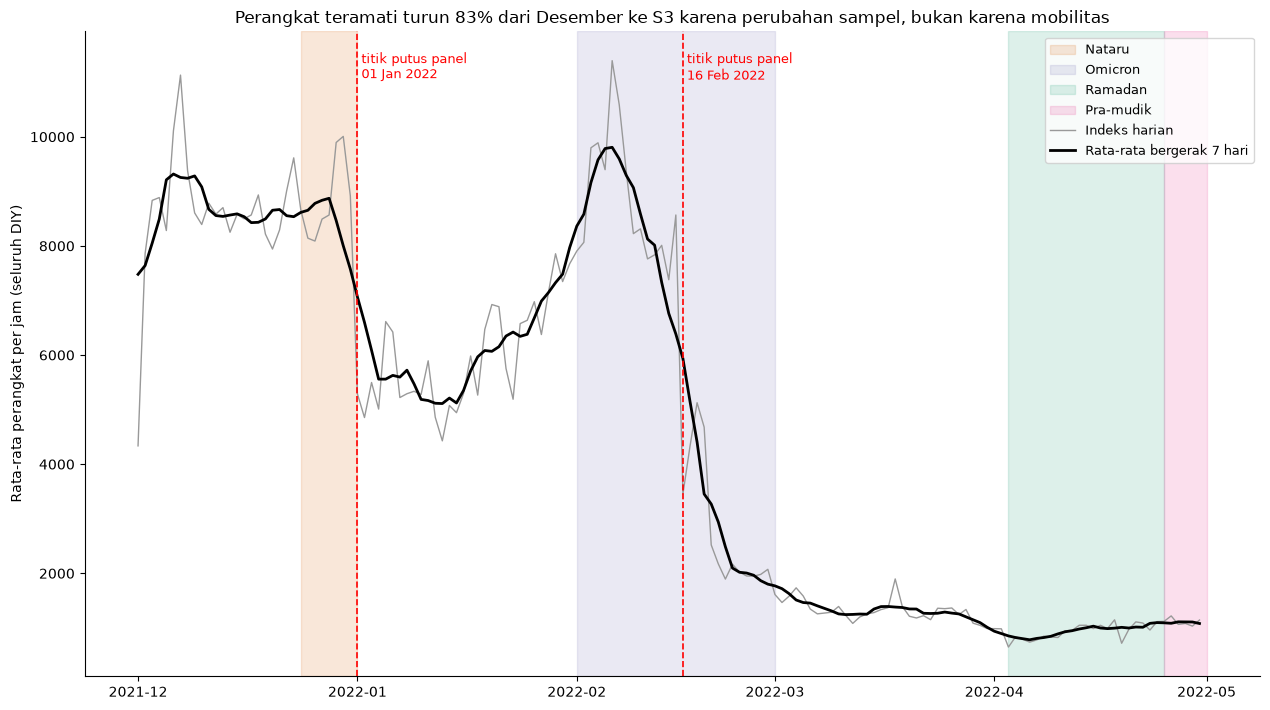

In [21]:
WARNA = {"Nataru": "#d95f02", "Omicron": "#7570b3", "Ramadan": "#1b9e77", "Pra-mudik": "#e7298a"}

s = idx_diy.drop(ANOMALI)
roll = s.rolling(7, center=True, min_periods=4).mean()
turun = (seg_tab["mean"].iloc[2] / seg_tab["mean"].iloc[0] - 1) * 100

fig, ax = plt.subplots(figsize=FIGSIZE)
for _, e in EVENTS.iterrows():
    ax.axvspan(e["mulai"], e["selesai"] + pd.Timedelta(days=1), color=WARNA[e["event"]], alpha=0.15, label=e["event"])
ax.plot(s.index, s.values, color="0.6", lw=1, label="Indeks harian")
ax.plot(roll.index, roll.values, color="black", lw=2, label="Rata-rata bergerak 7 hari")
for b in BREAKS:
    ax.axvline(b, color="red", ls="--", lw=1.2)
    ax.text(b, ax.get_ylim()[1] * 0.97, f" titik putus panel\n {b:%d %b %Y}", color="red", va="top", fontsize=9)
ax.set_ylabel("Rata-rata perangkat per jam (seluruh DIY)")
ax.set_title(f"Perangkat teramati turun {abs(turun):.0f}% dari Desember ke S3 karena perubahan sampel, bukan karena mobilitas", fontsize=12)
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "01_tren_harian.png")
plt.show()

Indeks harian stabil sekitar 8.500 perangkat/jam di Desember, kemudian turun tajam di kedua titik putus. Pola naik-turun di Januari-Februari, termasuk puncak awal Februari, juga mengikuti perubahan sampel, bukan peristiwa. Dari Desember ke S3, panel menyusut sekitar 83%. Karena itu analisis berikutnya memakai pangsa dan pembanding di dalam segmen.

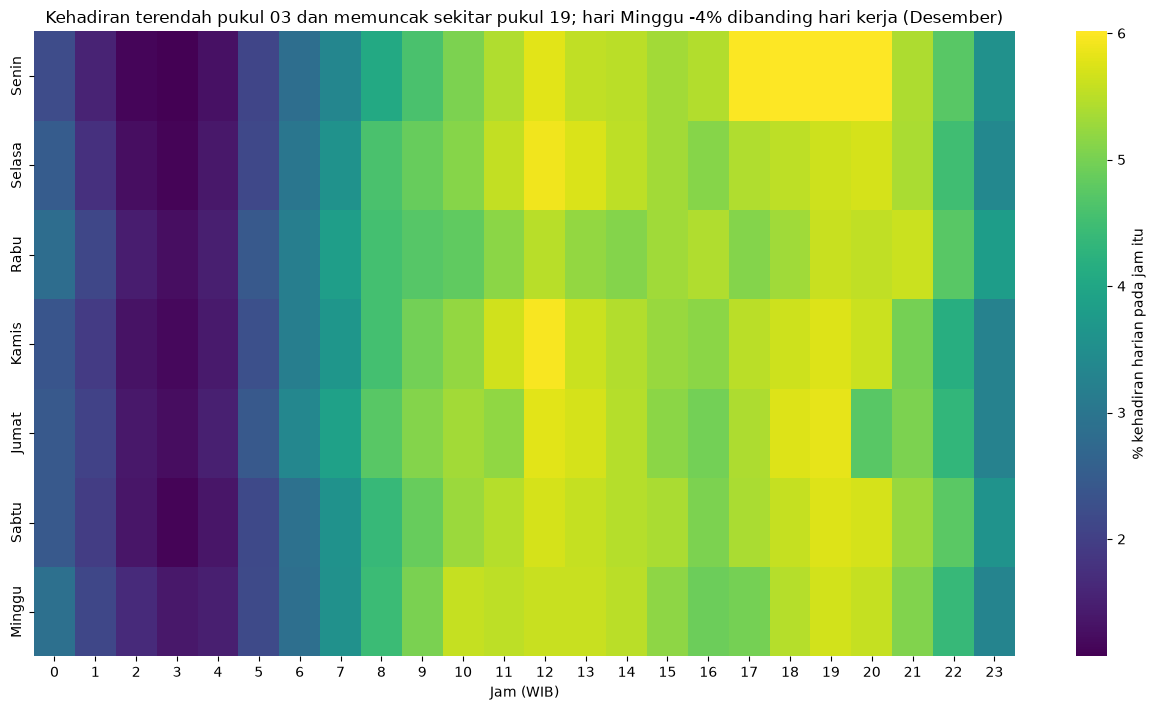

Hari Minggu vs rata-rata Senin-Jumat (indeks harian): -4.0 %


In [22]:
s1 = pres[pres["segmen"] == "S1"]
tot_jam = s1.groupby(["date", "hour"])["n_maids"].sum().reset_index()
tot_jam["pangsa_jam"] = tot_jam["n_maids"] / tot_jam.groupby("date")["n_maids"].transform("sum") * 100
tot_jam["dow"] = tot_jam["date"].dt.day_of_week
HARI = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]
hm = tot_jam[~tot_jam["date"].isin(LIBUR)].pivot_table(index="dow", columns="hour", values="pangsa_jam", aggfunc="mean")
hm.index = HARI
idx_hari = s1.groupby("date")["n_maids"].sum().to_frame("v").assign(dow=lambda x: x.index.day_of_week)
idx_hari = idx_hari[~idx_hari.index.isin(LIBUR)].groupby("dow")["v"].mean()
selisih_minggu = (idx_hari[6] / idx_hari[:5].mean() - 1) * 100
jam_puncak = hm.mean().idxmax()

fig, ax = plt.subplots(figsize=FIGSIZE)
sns.heatmap(hm, cmap="viridis", ax=ax, cbar_kws={"label": "% kehadiran harian pada jam itu"})
ax.set_xlabel("Jam (WIB)")
ax.set_ylabel("")
ax.set_title(f"Kehadiran terendah pukul 03 dan memuncak sekitar pukul {jam_puncak}; hari Minggu {selisih_minggu:+.0f}% dibanding hari kerja (Desember)", fontsize=12)
fig.tight_layout()
fig.savefig(FIG / "02_heatmap_hari_jam.png")
plt.show()
print("Hari Minggu vs rata-rata Senin-Jumat (indeks harian):", round(selisih_minggu, 1), "%")

Di Desember, kehadiran terendah terjadi pukul 03 (sekitar 1% kehadiran harian) dan naik sejak pukul 05. Kehadiran stabil tinggi dari pukul 11 sampai 20, dengan puncak sore pada hari Senin. Indeks harian hari Minggu 4% lebih rendah daripada rata-rata hari kerja. Pola ini sesuai dengan validasi temporal di README dataset.

## 7. Dampak Peristiwa (RQ1)

### 7.1 Nataru dengan angka mentah

Nataru dan acuannya berada di segmen panel yang sama (S1), sehingga angka mentah masih dapat dibandingkan secara wajar.

In [23]:
raw_s1 = idx_diy.to_frame("indeks").assign(dow=lambda x: x.index.day_of_week, date=lambda x: x.index, k="DIY")
raw_s1 = ubah(raw_s1[raw_s1.index < BREAKS[0]], ACUAN["des"], kolom="indeks", kunci="k")
nataru_raw_diy = raw_s1.loc["2021-12-24":"2021-12-31", "pct_change"].median()

kpw_s1 = ubah(daily_kpw[(daily_kpw["segmen"] == "S1") & daily_kpw["kapanewon_code"].isin(SET_A)], ACUAN["des"], kolom="indeks")
nataru_raw_kpw = (kpw_s1[kpw_s1["date"] >= "2021-12-24"].groupby("kapanewon_code")["pct_change"].median()
                  .to_frame("pct_mentah").join(nama))
print(f"Indeks DIY saat Nataru vs acuan (median): {nataru_raw_diy:+.1f}%")
nataru_raw_kpw.groupby("kab_kota")["pct_mentah"].median().round(1)

Indeks DIY saat Nataru vs acuan (median): -0.8%


kab_kota
BANTUL         2.3
GUNUNGKIDUL    3.1
KULON PROGO    5.3
SLEMAN        -1.7
YOGYAKARTA     1.0
Name: pct_mentah, dtype: float64

### 7.2 Perubahan pangsa per event

In [24]:
med_kpw = (baseline_change.groupby(["event", "kapanewon_code"])["pct_change"].median()
           .rename("pct_change").reset_index().merge(nama.reset_index(), on="kapanewon_code"))

kab_day = baseline_change.groupby(["event", "kab_kota", "date"])[["pangsa", "baseline"]].sum()
kab_day["pct"] = (kab_day["pangsa"] - kab_day["baseline"]) / kab_day["baseline"] * 100
tab_kab = kab_day.groupby(["event", "kab_kota"])["pct"].median().unstack(0)[EVENTS["event"]]
n_kab = baseline_change.groupby(["event", "kab_kota"])["kapanewon_code"].nunique().unstack(0)[EVENTS["event"]]
tab_kab.round(1).astype(str) + " (n=" + n_kab.fillna(0).astype(int).astype(str) + ")"

event,Nataru,Omicron,Ramadan,Pra-mudik
kab_kota,,,,
BANTUL,-1.0 (n=17),-8.8 (n=17),4.7 (n=7),-7.4 (n=7)
GUNUNGKIDUL,3.7 (n=9),-17.7 (n=9),38.1 (n=1),19.0 (n=1)
KULON PROGO,2.0 (n=11),-3.4 (n=11),NaN,NaN
SLEMAN,-1.5 (n=17),-11.4 (n=17),2.1 (n=11),13.5 (n=11)
YOGYAKARTA,0.5 (n=12),76.5 (n=12),-11.5 (n=7),-22.1 (n=7)


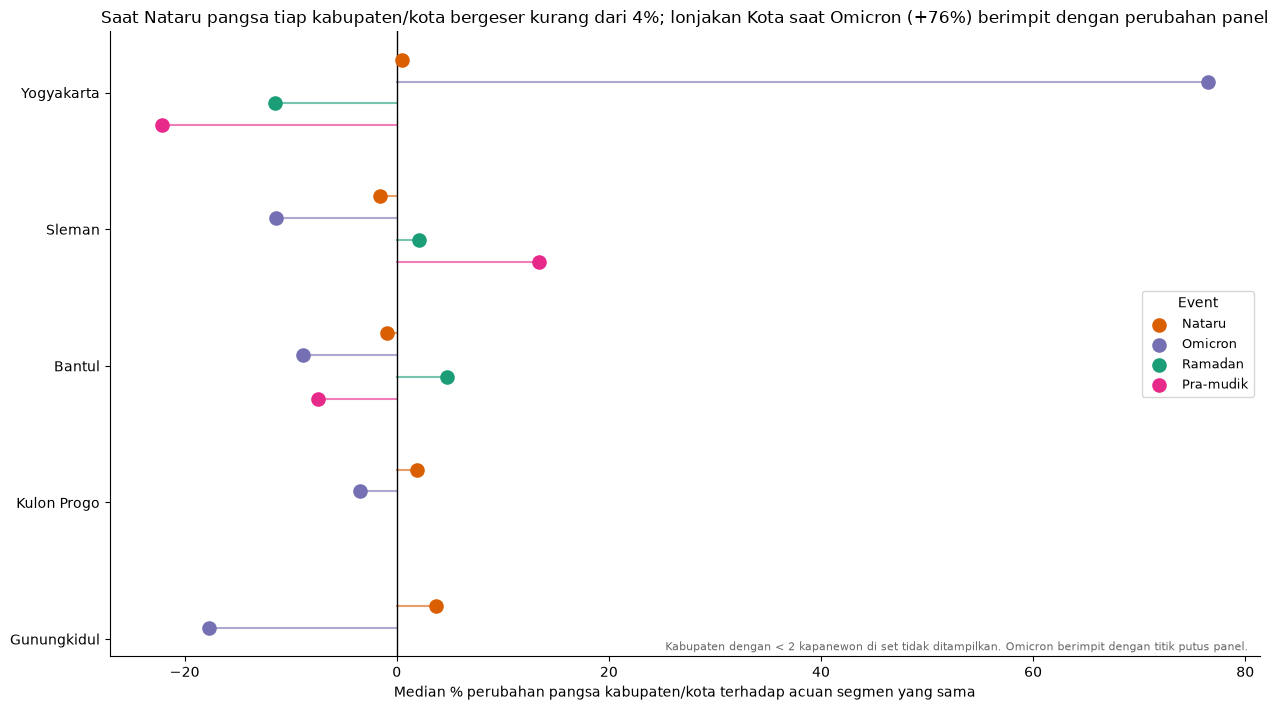

In [25]:
KAB_URUT = ["YOGYAKARTA", "SLEMAN", "BANTUL", "KULON PROGO", "GUNUNGKIDUL"]
plot_kab = tab_kab.stack().rename("pct").reset_index()
plot_kab = plot_kab[plot_kab["kab_kota"].isin(KAB_URUT)]
plot_kab = plot_kab.merge(n_kab.stack().rename("n").reset_index(), on=["kab_kota", "event"])
plot_kab = plot_kab[plot_kab["n"] >= 2]
kota_nataru = tab_kab.loc["YOGYAKARTA", "Nataru"]

fig, ax = plt.subplots(figsize=FIGSIZE)
y = {k: i for i, k in enumerate(KAB_URUT)}
off = dict(zip(EVENTS["event"], [-0.24, -0.08, 0.08, 0.24]))
for ev in EVENTS["event"]:
    g = plot_kab[plot_kab["event"] == ev]
    ax.scatter(g["pct"], g["kab_kota"].map(y) + off[ev], s=90, color=WARNA[ev], label=ev, zorder=3)
    for _, r in g.iterrows():
        ax.plot([0, r["pct"]], [y[r["kab_kota"]] + off[ev]] * 2, color=WARNA[ev], lw=1.5, alpha=0.6)
ax.axvline(0, color="black", lw=1)
ax.set_yticks(list(y.values()), [k.title() for k in KAB_URUT])
ax.invert_yaxis()
ax.set_xlabel("Median % perubahan pangsa kabupaten/kota terhadap acuan segmen yang sama")
maks_nataru = tab_kab["Nataru"].abs().max()
ax.set_title(f"Saat Nataru pangsa tiap kabupaten/kota bergeser kurang dari {np.ceil(maks_nataru):.0f}%; lonjakan Kota saat Omicron ({tab_kab.loc['YOGYAKARTA', 'Omicron']:+.0f}%) berimpit dengan perubahan panel", fontsize=12)
ax.legend(title="Event", fontsize=9)
ax.text(0.99, 0.01, "Kabupaten dengan < 2 kapanewon di set tidak ditampilkan. Omicron berimpit dengan titik putus panel.",
        transform=ax.transAxes, ha="right", fontsize=8, color="0.4")
fig.tight_layout()
fig.savefig(FIG / "03_perubahan_per_event.png")
plt.show()

Nataru hanya sedikit menggeser sebaran kehadiran. Pangsa kabupaten/kota berubah antara -1,5% (Sleman) dan +3,7% (Gunungkidul), dan indeks mentah DIY hampir sama dengan acuan (-0,8%). Selama masa Omicron (1-28 Februari), median perubahan pangsa harian Kota Yogyakarta terhadap acuan 6-19 Desember adalah +76,5%. Namun kenaikan ini sudah terlihat pada 1-15 Februari (+69,3%), sebelum titik putus, lalu menjadi +96,2% pada 16-28 Februari. Pangsa mingguan Kota juga naik bertahap, dari 9,8% (minggu yang berakhir 19 Desember) menjadi 21,8% (minggu yang berakhir 6 Maret), searah dengan menyusutnya panel. Efek Omicron karena itu **tidak dapat dipisahkan** dari perubahan komposisi sampel. Di kawasan perkotaan (Set B), pangsa Kota turun 11,5% saat Ramadan dan 22,1% menjelang mudik, sedangkan pangsa Sleman naik 13,5% menjelang mudik.

In [26]:
def top10(ev):
    d = med_kpw[med_kpw["event"] == ev].sort_values("pct_change")
    d = d[~d["kapanewon_code"].isin(KURANG_80_HARI)]
    fmt = lambda x: (x["kapanewon"].str.title() + " (" + x["kab_kota"].str.title() + ")").tolist()
    return pd.DataFrame({
        f"{ev}: naik": fmt(d.tail(10).iloc[::-1]), "% naik": d.tail(10).iloc[::-1]["pct_change"].round(1).tolist(),
        f"{ev}: turun": fmt(d.head(10)), "% turun": d.head(10)["pct_change"].round(1).tolist(),
    })


display(top10("Nataru"))
display(top10("Omicron"))

,Nataru: naik,% naik,Nataru: turun,% turun
0,Lendah (Kulon Progo),59.4,Pakem (Sleman),-36.3
1,Piyungan (Bantul),35.8,Gedangsari (Gunungkidul),-31.3
2,Patuk (Gunungkidul),25.3,Seyegan (Sleman),-22.6
3,Pengasih (Kulon Progo),22.0,Kretek (Bantul),-21.5
4,Galur (Kulon Progo),20.2,Gamping (Sleman),-17.7
5,Dlingo (Bantul),18.1,Kraton (Yogyakarta),-14.9
6,Kotagede (Yogyakarta),16.8,Sanden (Bantul),-14.9
7,Wonosari (Gunungkidul),15.5,Nglipar (Gunungkidul),-14.2
8,Wirobrajan (Yogyakarta),14.8,Jetis (Yogyakarta),-12.0
9,Berbah (Sleman),14.5,Moyudan (Sleman),-10.9


,Omicron: naik,% naik,Omicron: turun,% turun
0,Mantrijeron (Yogyakarta),396.3,Seyegan (Sleman),-83.2
1,Wirobrajan (Yogyakarta),392.3,Pakem (Sleman),-60.9
2,Danurejan (Yogyakarta),202.3,Gedangsari (Gunungkidul),-50.8
3,Jetis (Yogyakarta),168.9,Gamping (Sleman),-46.4
4,Tegalrejo (Yogyakarta),123.6,Imogiri (Bantul),-41.3
5,Panjatan (Kulon Progo),87.8,Tempel (Sleman),-41.2
6,Mergangsan (Yogyakarta),84.7,Srandakan (Bantul),-37.7
7,Patuk (Gunungkidul),83.9,Ponjong (Gunungkidul),-36.4
8,Gondokusuman (Yogyakarta),74.2,Kretek (Bantul),-35.9
9,Depok (Sleman),62.4,Samigaluh (Kulon Progo),-35.2


Masa Omicron dibagi di titik putus 16 Februari untuk melihat apakah perubahan pangsa muncul bertahap atau melompat bersamaan dengan perubahan panel.

In [27]:
om = baseline_change[baseline_change["event"] == "Omicron"].copy()
om["bagian"] = np.where(om["date"] < BREAKS[1], "1-15 Feb (S2)", "16-28 Feb (S3)")
om_kab = om.groupby(["bagian", "kab_kota", "date"])[["pangsa", "baseline"]].sum()
om_kab["pct"] = (om_kab["pangsa"] - om_kab["baseline"]) / om_kab["baseline"] * 100
om_split = om_kab.groupby(["kab_kota", "bagian"])["pct"].median().unstack().round(1)
display(om_split)

pa = pangsa(daily_kpw[daily_kpw["date"] < "2022-03-01"], SET_A)
kota_mingguan = pa[pa["kab_kota"] == "YOGYAKARTA"].groupby("date")["pangsa"].sum().resample("W-SUN").mean()
kota_mingguan.round(1).to_frame("pangsa Kota Yogyakarta (%)").T

bagian,1-15 Feb (S2),16-28 Feb (S3)
kab_kota,,
BANTUL,0.4,-16.2
GUNUNGKIDUL,-19.8,-6.1
KULON PROGO,-6.5,12.1
SLEMAN,-10.8,-14.4
YOGYAKARTA,69.3,96.2


date,2021-12-05,2021-12-12,2021-12-19,2021-12-26,2022-01-02,2022-01-09,2022-01-16,2022-01-23,2022-01-30,2022-02-06,2022-02-13,2022-02-20,2022-02-27,2022-03-06
pangsa Kota Yogyakarta (%),12.9,10.1,9.8,10.3,11.0,11.2,12.4,14.7,15.9,17.2,16.0,18.6,20.6,21.8


Saat Nataru, kenaikan pangsa terbesar terjadi di kapanewon pinggiran dan pedesaan, misalnya Lendah (+59%), Piyungan (+36%), dan Patuk (+25%). Penurunan terbesar terjadi di Pakem (-36%), Seyegan (-23%), dan Gamping (-18%). Nilai ekstrem di kapanewon kecil sensitif terhadap jumlah perangkat yang sedikit. Pada daftar Omicron, tujuh dari sepuluh kenaikan teratas adalah kapanewon di Kota Yogyakarta (hingga +396%). Pola ini lebih cocok dengan pergeseran komposisi sampel ke kawasan kota daripada dengan efek pandemi.

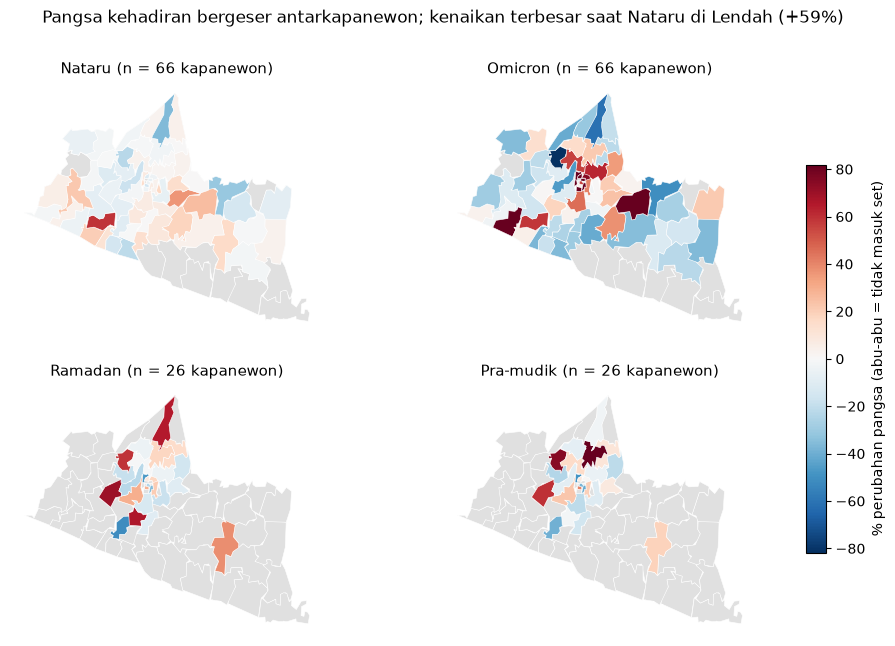

In [28]:
peta = geo.merge(med_kpw.pivot(index="kapanewon_code", columns="event", values="pct_change").reset_index(),
                 on="kapanewon_code", how="left")
batas = np.nanpercentile(np.abs(med_kpw["pct_change"]), 95)
norm = TwoSlopeNorm(vcenter=0, vmin=-batas, vmax=batas)
naik_kota = med_kpw.query("event == 'Nataru'").sort_values("pct_change").iloc[-1]

fig, axes = plt.subplots(2, 2, figsize=FIGSIZE)
for ax, ev in zip(axes.flat, EVENTS["event"]):
    peta.plot(color="0.88", ax=ax, edgecolor="white", lw=0.4)
    peta.dropna(subset=[ev]).plot(column=ev, cmap="RdBu_r", norm=norm, ax=ax, edgecolor="white", lw=0.4)
    n = peta[ev].notna().sum()
    ax.set_title(f"{ev} (n = {n} kapanewon)", fontsize=11)
    ax.set_axis_off()
sm = plt.cm.ScalarMappable(cmap="RdBu_r", norm=norm)
fig.colorbar(sm, ax=axes, shrink=0.7, label="% perubahan pangsa (abu-abu = tidak masuk set)")
fig.suptitle(f"Pangsa kehadiran bergeser antarkapanewon; kenaikan terbesar saat Nataru di {naik_kota['kapanewon'].title()} ({naik_kota['pct_change']:+.0f}%)", fontsize=12)
fig.savefig(FIG / "04_peta_perubahan_event.png", bbox_inches="tight")
plt.show()

Peta Nataru didominasi warna pucat: sebagian besar kapanewon berubah kurang dari 20%, dengan kenaikan tersebar di pinggiran Bantul, Kulon Progo, dan Gunungkidul utara. Peta Omicron jauh lebih kontras: inti kota berwarna merah dan wilayah luar berwarna biru, sesuai dengan artefak panel yang dijelaskan di atas. Peta Ramadan dan pra-mudik hanya mencakup 26 kapanewon perkotaan, dengan arah perubahan yang beragam antarkapanewon.

### 7.3 Profil per jam: acuan Maret vs Ramadan

Untuk setiap kapanewon di Set B dan setiap hari, dihitung bagian tiap jam terhadap total hari itu. Dengan cara ini besar panel tidak berpengaruh. Profil diambil dari median antarkapanewon, lalu rata-rata antarhari.

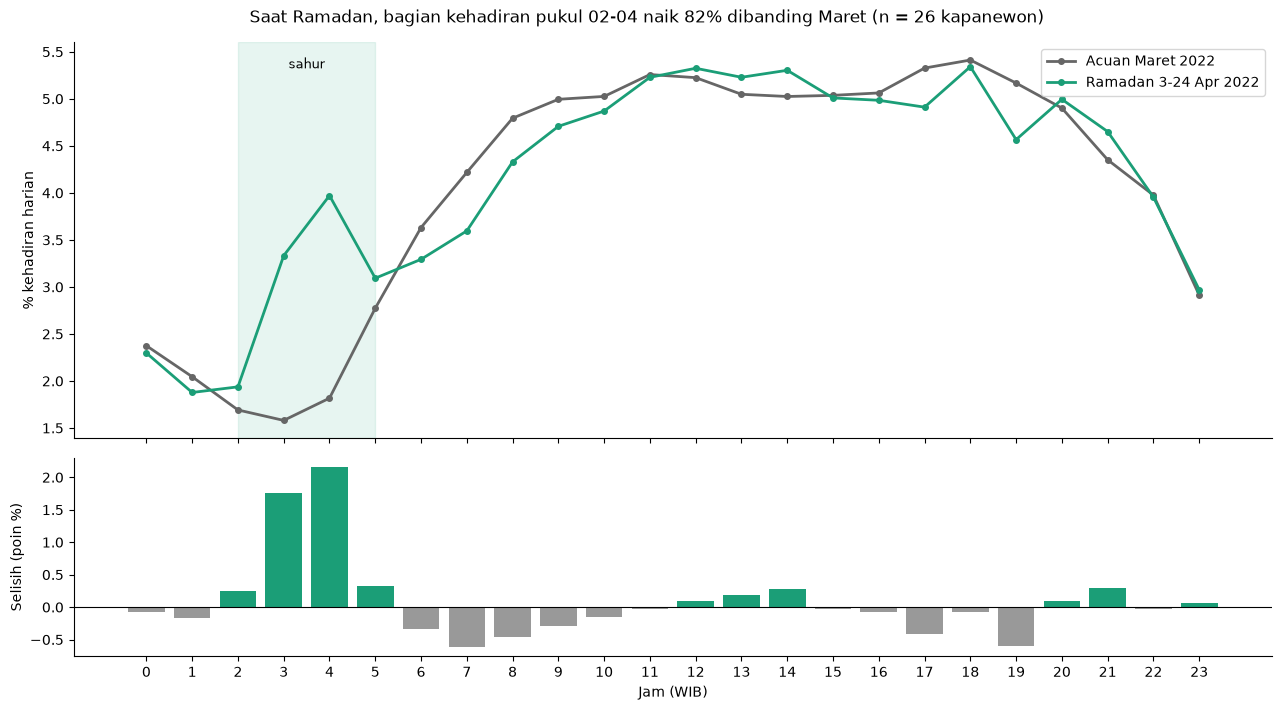

hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
selisih,-0.08,-0.17,0.25,1.75,2.15,0.32,-0.34,-0.62,-0.46,-0.29,-0.16,-0.03,0.1,0.18,0.28,-0.03,-0.08,-0.42,-0.07,-0.6,0.09,0.3,-0.02,0.06


In [29]:
pb = pres[pres["kapanewon_code"].isin(SET_B)].copy()
pb["bagian"] = pb["n_maids"] / pb.groupby(["kapanewon_code", "date"])["n_maids"].transform("sum") * 100
pb["periode"] = np.where(pb["date"].isin(ACUAN["mar"]), "Acuan Maret",
                np.where(pb["date"].between("2022-04-03", "2022-04-24"), "Ramadan", None))
prof = (pb.dropna(subset=["periode"]).groupby(["periode", "date", "hour"])["bagian"].median()
        .groupby(["periode", "hour"]).mean().unstack(0))
beda = prof["Ramadan"] - prof["Acuan Maret"]
sahur = (prof.loc[2:4, "Ramadan"].sum() / prof.loc[2:4, "Acuan Maret"].sum() - 1) * 100

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=FIGSIZE, sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax1.plot(prof.index, prof["Acuan Maret"], color="0.4", lw=2, marker="o", ms=4, label="Acuan Maret 2022")
ax1.plot(prof.index, prof["Ramadan"], color=WARNA["Ramadan"], lw=2, marker="o", ms=4, label="Ramadan 3-24 Apr 2022")
ax1.axvspan(2, 4.99, color=WARNA["Ramadan"], alpha=0.1)
ax1.text(3.5, ax1.get_ylim()[1] * 0.95, "sahur", ha="center", fontsize=9)
ax1.set_ylabel("% kehadiran harian")
ax1.legend()
ax2.bar(beda.index, beda.values, color=np.where(beda > 0, WARNA["Ramadan"], "0.6"))
ax2.axhline(0, color="black", lw=0.8)
ax2.set_ylabel("Selisih (poin %)")
ax2.set_xlabel("Jam (WIB)")
ax2.set_xticks(range(24))
fig.suptitle(f"Saat Ramadan, bagian kehadiran pukul 02-04 naik {sahur:.0f}% dibanding Maret (n = {len(SET_B)} kapanewon)", fontsize=12)
fig.tight_layout()
fig.savefig(FIG / "05_profil_jam_ramadan.png")
plt.show()
beda.round(2).to_frame("selisih").T

Profil jam paling jelas menunjukkan perubahan perilaku karena ukurannya tidak dipengaruhi besar panel. Saat Ramadan, bagian kehadiran pukul 03 naik dari 1,6% menjadi 3,3% dan pukul 04 dari 1,8% menjadi 4,0% kehadiran harian, sehingga jam 02-04 secara total naik 82%. Bagian pagi (pukul 06-09) dan pukul 17 serta 19 justru turun, sesuai dengan waktu sahur, berbuka, dan tarawih.

## 8. Pola Komuter & Arus Pergerakan (RQ2)

### 8.1 Rasio siang/malam

In [30]:
rasio = commuter_idx.pivot(index="kapanewon_code", columns="segmen", values="rasio")
stabil = pd.DataFrame({
    seg: {"rho vs S1": spearmanr(rasio[["S1", seg]].dropna())[0], "n": rasio[["S1", seg]].dropna().shape[0]}
    for seg in ["S2", "S3"]
}).T.round(3)
display(stabil)

r1 = rasio["S1"].dropna().to_frame("rasio").join(nama).sort_values("rasio")
pd.concat([r1.tail(8).iloc[::-1].reset_index(drop=True).add_prefix("tertinggi_"),
           r1.head(8).reset_index(drop=True).add_prefix("terendah_")], axis=1).round(2)

,rho vs S1,n
S2,0.617,64.0
S3,0.297,44.0


,tertinggi_rasio,tertinggi_kapanewon,tertinggi_kab_kota,terendah_rasio,terendah_kapanewon,terendah_kab_kota
0,4.51,PLAYEN,GUNUNGKIDUL,1.42,GONDOMANAN,YOGYAKARTA
1,4.37,NGLIPAR,GUNUNGKIDUL,2.27,DANUREJAN,YOGYAKARTA
2,4.33,PONJONG,GUNUNGKIDUL,2.36,PANJATAN,KULON PROGO
3,3.97,SAMIGALUH,KULON PROGO,2.54,MANTRIJERON,YOGYAKARTA
4,3.95,GEDANGSARI,GUNUNGKIDUL,2.55,KALIBAWANG,KULON PROGO
5,3.84,SEYEGAN,SLEMAN,2.55,DEPOK,SLEMAN
6,3.82,WONOSARI,GUNUNGKIDUL,2.60,WIROBRAJAN,YOGYAKARTA
7,3.76,WATES,KULON PROGO,2.61,UMBULHARJO,YOGYAKARTA


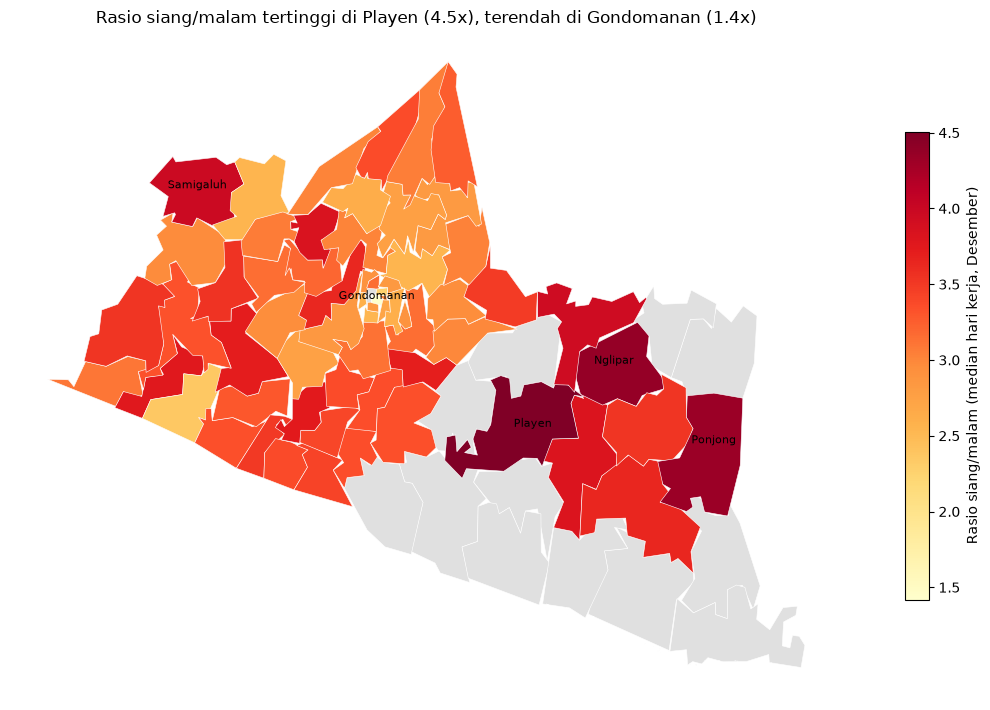

In [31]:
peta_r = geo.merge(r1["rasio"].reset_index(), on="kapanewon_code", how="left")
top = r1.iloc[-1]
fig, ax = plt.subplots(figsize=FIGSIZE)
peta_r.plot(color="0.88", ax=ax, edgecolor="white", lw=0.4)
peta_r.dropna(subset=["rasio"]).plot(column="rasio", cmap="YlOrRd", ax=ax, edgecolor="white", lw=0.4, legend=True,
                                     legend_kwds={"label": "Rasio siang/malam (median hari kerja, Desember)", "shrink": 0.7})
for kode, r in pd.concat([r1.tail(4), r1.head(1)]).iterrows():
    p = geo_utm.set_index("kapanewon_code").loc[[kode]].to_crs(4326).geometry.representative_point().iloc[0]
    ax.annotate(r["kapanewon"].title(), (p.x, p.y), fontsize=8, ha="center")
ax.set_axis_off()
low = r1.iloc[0]
ax.set_title(f"Rasio siang/malam tertinggi di {top['kapanewon'].title()} ({top['rasio']:.1f}x), terendah di {low['kapanewon'].title()} ({low['rasio']:.1f}x)", fontsize=12)
fig.tight_layout()
fig.savefig(FIG / "06_peta_rasio_siang_malam.png")
plt.show()

Di semua kapanewon, kehadiran siang lebih tinggi daripada malam (rasio 1,4-4,5), karena perangkat lebih aktif di siang hari. Rasio tertinggi justru berada di kapanewon pedesaan Gunungkidul (Playen 4,5; Nglipar 4,4; Ponjong 4,3), sedangkan yang terendah ada di Gondomanan (1,4), pusat wisata malam Malioboro. Peringkat rasio cukup stabil dari S1 ke S2 (Spearman rho = 0,62), tetapi lemah di S3 (rho = 0,30) ketika panel sudah kecil.

### 8.2 Arus asal-tujuan Desember-Februari

In [32]:
antar = od[od["origin_code"] != od["dest_code"]].copy()
top15 = antar.sort_values("n_maids", ascending=False).head(15)
top15_tab = top15.assign(asal=top15["origin_kapanewon"].str.title(), tujuan=top15["dest_kapanewon"].str.title())[
    ["asal", "tujuan", "n_maids", "proporsi", "bulan"]].round(1).reset_index(drop=True)
display(top15_tab)
print("Proporsi tertinggi per asal (arus antar-kapanewon, minimal 3 bulan terpublikasi):")
display(antar[antar["bulan"] == 3].sort_values("proporsi", ascending=False).head(10)
        [["origin_kapanewon", "dest_kapanewon", "n_maids", "proporsi"]].round(1).reset_index(drop=True))

,asal,tujuan,n_maids,proporsi,bulan
0,Ngaglik,Depok,1120.3,9.1,3
1,Ngaglik,Pakem,1118.0,7.3,3
2,Banguntapan,Umbulharjo,1092.7,8.4,3
3,Ngaglik,Ngemplak,1016.3,8.1,3
4,Ngemplak,Depok,988.3,13.2,3
5,Ngemplak,Ngaglik,954.0,12.7,3
6,Banguntapan,Depok,908.0,7.2,3
7,Depok,Ngemplak,887.3,5.3,3
8,Depok,Banguntapan,858.3,5.1,3
9,Depok,Ngaglik,842.0,5.0,3


Proporsi tertinggi per asal (arus antar-kapanewon, minimal 3 bulan terpublikasi):


,origin_kapanewon,dest_kapanewon,n_maids,proporsi
0,KOTAGEDE,BANGUNTAPAN,638.7,22.8
1,TANJUNGSARI,WONOSARI,29.3,22.6
2,KOTAGEDE,UMBULHARJO,596.3,21.3
3,RONGKOP,SEMANU,18.7,21.2
4,GALUR,LENDAH,121.3,20.2
5,GONDOMANAN,SLEMAN,497.3,18.4
6,PENGASIH,WATES,338.7,16.7
7,PAKUALAMAN,DANUREJAN,174.0,16.3
8,GIRIMULYO,NANGGULAN,56.3,15.2
9,PAKUALAMAN,MERGANGSAN,159.3,15.0


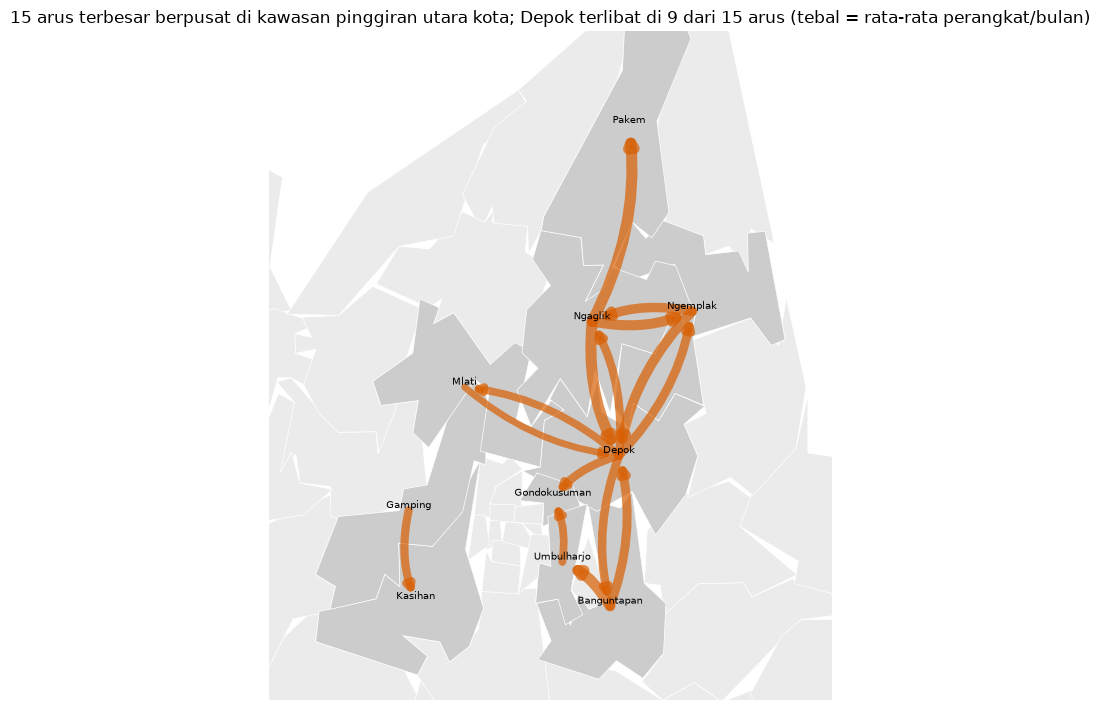

In [33]:
c = centroid.to_crs(4326)
tuj = top15["dest_kapanewon"].value_counts()
fig, ax = plt.subplots(figsize=FIGSIZE)
geo.plot(color="0.92", edgecolor="white", lw=0.5, ax=ax)
geo[geo["kapanewon_code"].isin(top15[["origin_code", "dest_code"]].values.ravel())].plot(color="0.8", edgecolor="white", lw=0.5, ax=ax)
w = top15["n_maids"] / top15["n_maids"].max() * 8
for (_, r), lw in zip(top15.iterrows(), w):
    a, b = c[r["origin_code"]], c[r["dest_code"]]
    ax.annotate("", xy=(b.x, b.y), xytext=(a.x, a.y),
                arrowprops=dict(arrowstyle="-|>", lw=lw, color="#d95f02", alpha=0.7, shrinkA=0, shrinkB=4,
                                connectionstyle="arc3,rad=0.15"))
for kode in set(top15["origin_code"]) | set(top15["dest_code"]):
    ax.annotate(nama.loc[kode, "kapanewon"].title(), (c[kode].x, c[kode].y), fontsize=7, ha="center", va="bottom")
b = top15[["origin_code", "dest_code"]].values.ravel()
xs, ys = c[b].x, c[b].y
ax.set_xlim(xs.min() - 0.06, xs.max() + 0.06)
ax.set_ylim(ys.min() - 0.04, ys.max() + 0.04)
ax.set_axis_off()
libat = pd.concat([top15["origin_kapanewon"], top15["dest_kapanewon"]]).value_counts()
ax.set_title(f"15 arus terbesar berpusat di kawasan pinggiran utara kota; {libat.index[0].title()} terlibat di {libat.iloc[0]} dari 15 arus (tebal = rata-rata perangkat/bulan)", fontsize=12)
fig.tight_layout()
fig.savefig(FIG / "07_peta_arus_od.png")
plt.show()

Ke-15 arus terbesar semuanya berada di Sleman, Bantul utara, dan Kota Yogyakarta. Depok terlibat di 9 dari 15 arus, disusul Ngaglik (5) dan Ngemplak (4), sedangkan arus ke kapanewon Kota hanya muncul 3 kali (ke Gondokusuman dan Umbulharjo). Arus terbesar adalah Ngaglik ke Depok, rata-rata 1.120 perangkat/bulan atau 9,1% perangkat dari Ngaglik. Jika dilihat dari proporsi per asal, keterikatan terkuat terjadi antara kapanewon yang bertetangga, misalnya Kotagede ke Banguntapan (22,8%) dan Tanjungsari ke Wonosari (22,6%). Pada net inflow, ke-14 kapanewon Kota Yogyakarta memiliki median indeks +0,33, sedangkan keempat kabupaten bernilai negatif (-0,04 sampai -0,11). Artinya Kota berperan sebagai tujuan kunjungan siang.

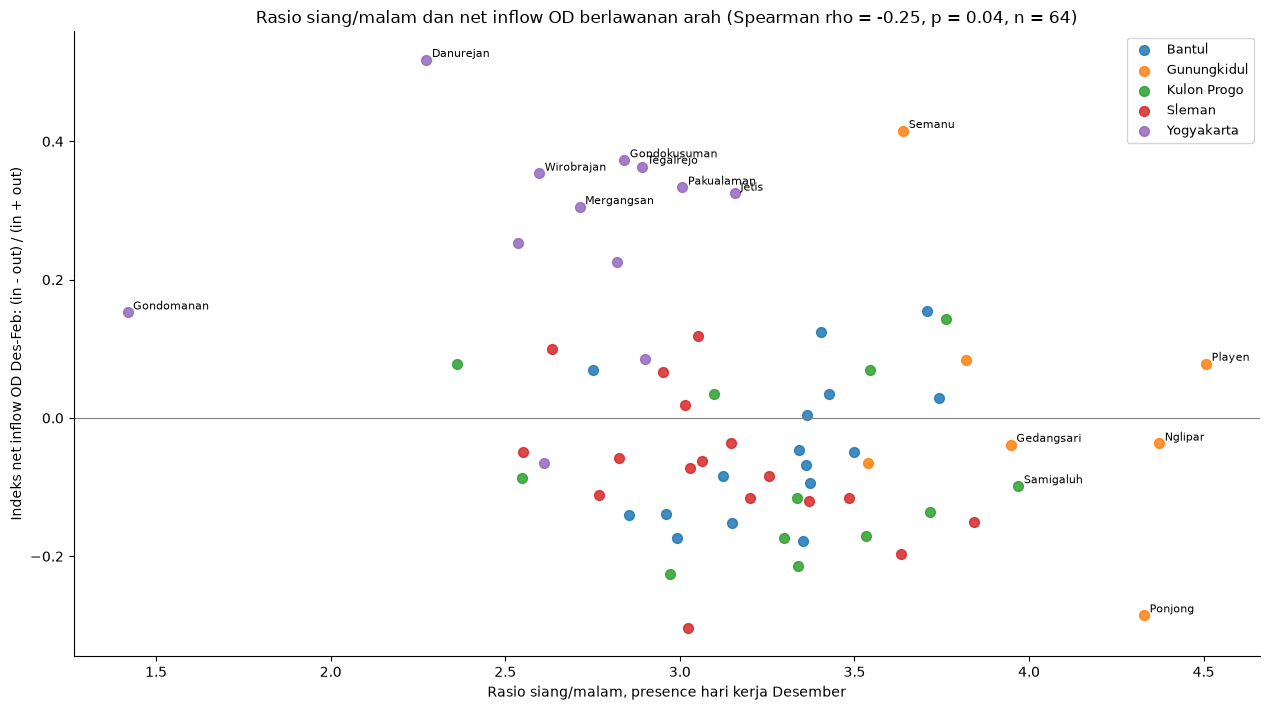

rho (indeks net) = -0.253, p = 0.043; rho (net mentah) = -0.162


In [34]:
val = r1[["rasio", "kapanewon", "kab_kota"]].join(arus.set_index("kapanewon_code")[["net", "net_idx"]], how="inner")
rho, pval = spearmanr(val["rasio"], val["net_idx"])
rho_raw, _ = spearmanr(val["rasio"], val["net"])

fig, ax = plt.subplots(figsize=FIGSIZE)
for kab, g in val.groupby("kab_kota"):
    ax.scatter(g["rasio"], g["net_idx"], s=50, label=kab.title(), alpha=0.85)
for _, r in val[(val["rasio"] > val["rasio"].quantile(0.93)) | (val["net_idx"] > 0.3) | (val["rasio"] < 2)].iterrows():
    ax.annotate(r["kapanewon"].title(), (r["rasio"], r["net_idx"]), fontsize=8, xytext=(4, 2), textcoords="offset points")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xlabel("Rasio siang/malam, presence hari kerja Desember")
ax.set_ylabel("Indeks net inflow OD Des-Feb: (in - out) / (in + out)")
arah = "searah" if rho > 0 else "berlawanan arah"
ax.set_title(f"Rasio siang/malam dan net inflow OD {arah} (Spearman rho = {rho:.2f}, p = {pval:.2f}, n = {len(val)})", fontsize=12)
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "08_scatter_validasi.png")
plt.show()
print(f"rho (indeks net) = {rho:.3f}, p = {pval:.2g}; rho (net mentah) = {rho_raw:.3f}")

Validasi silang **tidak mendukung** dugaan awal. Rasio siang/malam berkorelasi negatif lemah dengan net inflow (rho = -0,25, p = 0,04). Kapanewon Kota memiliki net inflow tertinggi tetapi rasio siang/malam relatif rendah, sedangkan kapanewon pedesaan Gunungkidul memiliki rasio tinggi dengan net inflow sekitar nol. Rasio ini tidak berkorelasi dengan besar kehadiran malam (rho = -0,09), jadi penyebabnya bukan ukuran wilayah. Penjelasan yang lebih mungkin adalah bahwa `n_maids` hanya mencatat perangkat yang aktif mengirim lokasi. Di kota, aktivitas malam tetap tinggi (wisata, hiburan, mahasiswa), sedangkan di desa perangkat jarang aktif pada malam hari. Akibatnya rasio siang/malam dari data ini lebih mencerminkan pola aktivitas malam daripada peran wilayah sebagai pusat kerja. Untuk RQ2, data OD lebih dapat diandalkan.

Diagnostik: apakah rasio siang/malam lebih dipengaruhi oleh rendahnya kehadiran malam di wilayah sepi daripada oleh peran wilayah sebagai pusat aktivitas?

In [35]:
diag = r1.join(commuter_idx[commuter_idx["segmen"] == "S1"].set_index("kapanewon_code")[["malam", "siang"]])
diag = diag.join(arus.set_index("kapanewon_code")["net_idx"])
pd.DataFrame({
    "rho": [spearmanr(diag["rasio"], diag["malam"])[0], spearmanr(diag["net_idx"], diag["malam"])[0],
            spearmanr(diag["net_idx"], diag["siang"])[0]],
}, index=["rasio vs kehadiran malam", "net inflow vs kehadiran malam", "net inflow vs kehadiran siang"]).round(3)

,rho
rasio vs kehadiran malam,-0.086
net inflow vs kehadiran malam,-0.153
net inflow vs kehadiran siang,-0.206


Uji tambahan: apakah korelasi negatif disebabkan oleh supresi k-anonim pada jam malam? Korelasi dihitung ulang hanya pada kapanewon yang seluruh slot jam 00-05 di hari kerja Desember terpublikasi (100%).

In [36]:
k_malam = kerja[(kerja["segmen"] == "S1") & kerja["hour"].between(0, 5)]
lengkap_malam = k_malam.groupby("kapanewon_code").size() / (k_malam["date"].nunique() * 6) * 100
uji = {
    "semua kapanewon": val,
    "malam lengkap 100%": val[val.index.isin(lengkap_malam.index[lengkap_malam == 100])],
}
uji["malam lengkap, tanpa Kota"] = uji["malam lengkap 100%"].query("kab_kota != 'YOGYAKARTA'")
pd.DataFrame({k: dict(zip(["rho", "p", "n"], [*spearmanr(v["rasio"], v["net_idx"]), len(v)])) for k, v in uji.items()}).T.round(3)

,rho,p,n
semua kapanewon,-0.253,0.043,64.0
malam lengkap 100%,-0.163,0.322,39.0
"malam lengkap, tanpa Kota",0.197,0.289,31.0


Pada 39 kapanewon yang jam malamnya lengkap, korelasi melemah menjadi rho = -0,16 (p = 0,32) dan tidak lagi signifikan. Jika kapanewon Kota juga dikeluarkan, nilainya menjadi rho = +0,20 (p = 0,29), juga tidak signifikan. Artinya supresi malam di kapanewon pedesaan ikut memperkuat tanda negatif, tetapi tidak menyembunyikan hubungan positif. Pada data yang lengkap pun rasio siang/malam tidak berkaitan dengan net inflow. Korelasi negatif pada semua kapanewon terutama berasal dari dua kelompok: kapanewon Kota (net inflow tinggi, rasio rendah) dan kapanewon pedesaan yang jam malamnya sering tersupresi.

## 9. Keterbatasan

1. **Perangkat bukan penduduk.** Angka adalah *presence* perangkat dari SDK aplikasi (k-anonim, k = 5), bukan jumlah orang. Representativitas berbeda antarwilayah.
2. **Panel tidak stabil.** Ukuran sampel turun sekitar 83% dengan titik putus 1 Januari dan 16 Februari 2022. Perubahan total mobilitas DIY tidak dapat diukur, dan efek Omicron tidak dapat dipisahkan dari perubahan sampel.
3. **Supresi tidak acak.** Wilayah pedesaan lebih banyak tersupresi, terutama di Maret-April. Hasil Ramadan dan pra-mudik hanya berlaku untuk 26 kapanewon perkotaan (Set B), dan Kulon Progo tidak terwakili.
4. **Pangsa bersifat relatif.** Kenaikan pangsa suatu wilayah dapat berasal dari penurunan di wilayah lain.
5. **Rasio siang/malam** dipengaruhi tingkat aktivitas perangkat di malam hari dan supresi jam malam di wilayah sepi, sehingga bukan ukuran langsung peran komuter.
6. **OD** menghitung pengunjung unik per bulan, bukan jumlah perjalanan, dan hanya memakai Desember-Februari. Outflow dapat menghitung satu perangkat di beberapa tujuan.
7. **Kalender peristiwa** disusun manual dan hanya memakai rentang tanggal kasar. Semua hasil bersifat deskriptif dan tidak menunjukkan sebab-akibat.
8. **Batas wilayah** berasal dari sumber turunan (cahyadsn melalui idn-geojson). Semua kode cocok dengan dataset, tetapi bentuk poligon sudah disederhanakan.

## 10. Kesimpulan

1. **Masalah data menentukan desain analisis.** Panel perangkat menyusut sekitar 83% (8.663 menjadi 1.442 perangkat/jam) dengan dua titik putus. Karena itu RQ1 dijawab melalui pangsa pada himpunan kapanewon tetap dan pembanding di segmen yang sama.
2. **Nataru hampir tidak menggeser sebaran kehadiran.** Indeks DIY -0,8% terhadap acuan, dan pangsa kabupaten/kota bergeser antara -1,5% dan +3,7%. Kenaikan terbesar ada di kapanewon pinggiran, seperti Lendah (+59%) dan Piyungan (+36%).
3. **Lonjakan pangsa Kota Yogyakarta saat Omicron (+76%) tidak dapat ditafsirkan sebagai efek pandemi**, karena kenaikannya bertahap dan berimpit dengan penyusutan panel.
4. **Ramadan memberi sinyal perilaku yang paling jelas.** Bagian kehadiran pukul 02-04 naik 82% dibanding Maret, sedangkan kehadiran pagi dan saat berbuka turun. Menjelang mudik, pangsa Kota turun 22% dan pangsa Sleman naik 14% di kawasan perkotaan.
5. **Kota Yogyakarta adalah tujuan aktivitas siang menurut OD** (median indeks net inflow +0,33 dibanding negatif di keempat kabupaten), sedangkan arus terbesar membentuk jaringan di sekitar Depok-Ngaglik-Ngemplak (Sleman). Rasio siang/malam dari data presence tidak memvalidasi temuan ini. Pada semua kapanewon rho = -0,25 (p = 0,04), dan pada 39 kapanewon dengan jam malam lengkap rho = -0,16 (p = 0,32). Ukuran tersebut kurang tepat untuk mengidentifikasi pusat aktivitas pada dataset ini.

## 11. Referensi

1. Widyawan, Pratama, A. R., Ariansyah, A., Farda, N. M., Pramana, S., & Miller, O. (2026). *JogjaPulse: An Aggregated Spatio-Temporal Mobility Dataset for Yogyakarta, Indonesia* (v1) [Dataset]. Zenodo. https://doi.org/10.5281/zenodo.23157460 (CC BY 4.0)
2. Google LLC. *COVID-19 Community Mobility Reports*: catatan metodologi baseline (median per hari-dalam-minggu). https://www.google.com/covid19/mobility/
3. cahyadsn. *wilayah_boundaries*. https://github.com/cahyadsn/wilayah_boundaries, diakses melalui aaronsanger. *idn-geojson*. https://github.com/aaronsanger/idn-geojson
4. Kementerian Agama RI. Hasil sidang isbat awal Ramadan 1443 H (1 Ramadan = 3 April 2022).
5. SKB Menteri Agama, Menteri Ketenagakerjaan, dan Menteri PANRB tentang Hari Libur Nasional dan Cuti Bersama Tahun 2022.
6. Satuan Tugas Penanganan COVID-19. Data perkembangan kasus harian COVID-19 Indonesia, Februari 2022.